# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Maribao, Jake Agustin
- _Student No._: 2023-08777
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

![INT](int_a_error.png)![int](int_a_mc.png)

_Figure 1. Test a, y = √(9 - 4x²) from x = 0 to 3/2. Left: |error| of the integral relative to scipy.integrate.quad vs n, with the trapezoidal rule dashed, Simpson's 1/3 rule solid, Simpson's 3/8 rule dash-dotted and Monte Carlo (mean of 20 runs) in blue. Right: Monte Carlo points between the curve and the x-axis (N = 3000). The exact integral is 9π/8 ≈ 3.5343._

![INT](int_b_error.png)![int](int_b_mc.png)

_Figure 2. Test b, y = -x² + 1 from x = -2 to 2. Both Simpson's rules are exact for this parabola, so their errors sit at the rounding floor. In the Monte Carlo plot, red points mark the regions where f < 0. The exact integral is -4/3 and the total area is 4._

![INT](int_c_error.png)![int](int_c_mc.png)

_Figure 3. Test c, y = cos(x)√x from x = 0 to π. The curve crosses the x-axis at x = π/2, so the Monte Carlo points switch from blue to red there. The scipy.integrate.quad reference gives an integral of -0.894831 and a total area of 2.302907._


### Report discussion

**Explain the figures.** In each error plot, the trapezoidal rule falls as n^-2 for the parabola in (b), while both Simpson's rules are exact there because they fit a parabola (1/3) or a cubic (3/8), so their error sits at the rounding floor near 10^-16. In (a) and (c), all three grid rules slow to n^-1.5 because √(9 - 4x²) and √x have an infinite slope at an endpoint, and the 1/3 rule beats the 3/8 rule by a factor of 1.2. Monte Carlo falls only as N^-0.5, so at 12288 points it is still off by about 10^-2 while both Simpson's rules are near 4×10^-7. The scatter plots show the accepted Monte Carlo points, blue between the x-axis and the curve where f > 0 and red where f < 0, and the signed area is the box area times (blue - red)/N.

**Why can Monte Carlo give the integral, and when are Newton-Cotes methods more suitable?** Each random point in the box lands between the curve and the x-axis with a probability equal to that area divided by the box area. By the law of large numbers, the fraction of hits converges to this probability, so the box area times the fraction gives the area, with blue and red hits counted with opposite signs for the integral. The count is random, so its error falls as N^-1/2 however smooth f is. Newton-Cotes methods are more suitable for low-dimensional integrals of smooth functions, where their errors fall as h² or h⁴ and reach 10^-7 with the same number of evaluations that leaves Monte Carlo at 10^-2. Monte Carlo becomes the better choice in many dimensions or over irregular regions, because a grid needs n^d points in d dimensions while the N^-1/2 rate does not depend on d.

### Other comments
- The total area is found by applying each grid rule to |f|, which has a corner at every root (x = ±1 in b and x = π/2 in c). Near a corner the rules lose accuracy unless a node lands on the root. With n = 1002 the nodes miss x = ±1 in test b, so the trapezoidal and 1/3 rule total areas are off by 1.6×10^-5 and 5×10^-6, even though the 1/3 rule gives the signed integral exactly.
- The Monte Carlo box is sized from 1001 samples of f with a 5% margin. A function with a narrow spike between those samples could stick out of the box, and the part outside would be missed.
- `simpson()` and `simpson38()` raise an error when n is not even or not a multiple of 3, instead of silently changing it, so the number of divisions used is always the one requested. That is why the tests use n = 1002, which suits both.
- scipy has no 3/8 rule, so `simpson38()` is checked against `quad` and against a cubic, which it must integrate exactly.
- For a smooth function the 3/8 rule has the same h⁴ order as the 1/3 rule but a 9/4 times larger error constant (checked on e^x), so its main use is when n is a multiple of 3 instead of even.
- Reflection: I expected Simpson's rule to be far better in every test. Tests a and c showed that the smoothness of the function matters as much as the order of the method.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy import integrate

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



### Integration functions

**Approach.**
- `evaluate()` lets every method accept any function: vectorized NumPy functions run directly, scalar-only functions (such as `math.sqrt`) are evaluated point by point, and constants are broadcast.
- The trapezoidal rule and both Simpson's rules are a weighted sum over n + 1 equally spaced nodes, so they share `_grid_rule()` and differ only in their weights: h(1/2, 1, ..., 1, 1/2), (h/3)(1, 4, 2, 4, ..., 4, 1) and (3h/8)(1, 3, 3, 2, 3, 3, 2, ..., 3, 3, 1).
- The signed area is the weighted sum of f, and the total area is the same sum with |f|, which counts the parts below the x-axis as positive.
- Monte Carlo uses the hit-or-miss method. Random points fill a box around the curve and the x-axis, a point counts +1 between the axis and the curve where f > 0 and -1 where f < 0, and the area is the box area times the fraction of hits.

In [2]:
def evaluate(f, x):
    """Evaluate f on the array x, even if f only accepts scalars (e.g. math.sqrt) or returns a constant."""
    try:
        y = np.asarray(f(x), dtype=float)
    except TypeError:                                   # scalar-only function: evaluate point by point
        y = np.array([f(xi) for xi in x], dtype=float)
    return np.broadcast_to(y, x.shape)


def _grid_rule(f, a, b, n, weights):
    """Apply a weighted sum over n+1 equally spaced nodes. Returns (total area, signed area)."""
    x = np.linspace(a, b, n + 1)
    wy = weights*evaluate(f, x)
    return np.sum(np.abs(wy)), np.sum(wy)               # |w*y| keeps the total area positive even if b < a


def trapezoidal(f, a, b, n):
    """Trapezoidal rule with n divisions. Returns (total area, signed area)."""
    if n < 1:
        raise ValueError("n must be at least 1")
    h = (b - a)/n
    w = np.full(n + 1, h)
    w[[0, -1]] = h/2                                    # weights h/2, h, h, ..., h, h/2
    return _grid_rule(f, a, b, n, w)


def simpson(f, a, b, n):
    """Simpson's 1/3 rule with n divisions (n must be even). Returns (total area, signed area)."""
    if n < 2 or n % 2:
        raise ValueError("Simpson's rule needs an even number of divisions, n >= 2")
    h = (b - a)/n
    w = np.full(n + 1, 2*h/3)
    w[1::2] = 4*h/3                                     # weights h/3 * (1, 4, 2, 4, ..., 2, 4, 1)
    w[[0, -1]] = h/3
    return _grid_rule(f, a, b, n, w)


def simpson38(f, a, b, n):
    """Simpson's 3/8 rule with n divisions (n must be a multiple of 3). Returns (total area, signed area)."""
    if n < 3 or n % 3:
        raise ValueError("Simpson's 3/8 rule needs a multiple of 3 divisions, n >= 3")
    h = (b - a)/n
    w = np.full(n + 1, 9*h/8)
    w[3::3] = 6*h/8                                     # weights 3h/8 * (1, 3, 3, 2, 3, 3, 2, ..., 3, 3, 1)
    w[[0, -1]] = 3*h/8
    return _grid_rule(f, a, b, n, w)


def monte_carlo(f, a, b, n, seed=None, return_points=False):
    """Hit-or-miss Monte Carlo with n random points. Returns (total area, signed area).

    Points are drawn uniformly in a box that spans [a, b] and the range of f (including y = 0).
    A point between the x-axis and the curve counts as +1 if f > 0 and as -1 if f < 0.
    """
    x_grid = np.linspace(a, b, 1001)                    # locate the box from a dense sample of f
    y_grid = evaluate(f, x_grid)
    y_lo, y_hi = min(y_grid.min(), 0), max(y_grid.max(), 0)
    pad = 0.05*(y_hi - y_lo)                            # margin in case the sample misses the true extremes
    y_lo, y_hi = y_lo - pad*(y_lo < 0), y_hi + pad*(y_hi > 0)
    box = (b - a)*(y_hi - y_lo)

    rng = np.random.default_rng(seed)
    x = rng.uniform(a, b, n)
    y = rng.uniform(y_lo, y_hi, n)
    fx = evaluate(f, x)
    above = (0 < y) & (y < fx)                          # between the axis and the curve, where f > 0
    below = (fx < y) & (y < 0)                          # between the curve and the axis, where f < 0

    total = abs(box)*(above.sum() + below.sum())/n
    signed = box*(above.sum() - below.sum())/n
    if return_points:
        return total, signed, (x, y, above, below)
    return total, signed

### Tests (checked with `scipy.integrate.quad`)

Each test is checked against `scipy.integrate.quad` (on f for the integral and on |f| for the total area). `scipy.integrate.trapezoid` and `scipy.integrate.simpson` are also run on the same nodes, and they must agree with our functions to rounding error. scipy has no 3/8 rule, so `simpson38()` is checked against `quad` and against a cubic, which it integrates exactly.

In [3]:
tests = {
    'a': (lambda x: np.sqrt(9 - 4*x**2), 0, 3/2, 'y = sqrt(9 - 4x²)'),
    'b': (lambda x: -x**2 + 1, -2, 2, 'y = -x² + 1'),
    'c': (lambda x: np.cos(x)*np.sqrt(x), 0, np.pi, 'y = cos(x) sqrt(x)'),
}

n_div = 1002          # divisions for the grid rules (even for Simpson 1/3, a multiple of 3 for Simpson 3/8)
n_mc = 10**6          # random points for Monte Carlo

reference = {}
for key, (f, a, b, label) in tests.items():
    # scipy references: quad for the integral, quad on |f| for the total area
    ref_signed = integrate.quad(f, a, b)[0]
    ref_total = integrate.quad(lambda x: abs(f(x)), a, b, limit=200)[0]
    reference[key] = (ref_total, ref_signed)

    # scipy's own trapezoid and simpson on the same nodes, to check our implementations
    x = np.linspace(a, b, n_div + 1)
    y = f(x)
    sp_trap = (integrate.trapezoid(np.abs(y), x), integrate.trapezoid(y, x))
    sp_simp = (integrate.simpson(np.abs(y), x=x), integrate.simpson(y, x=x))

    print(f'{key}) {label}, x from {a:g} to {b:.4g}')
    print(f'   {"method":32s} {"total area":>12s} {"signed area":>12s}')
    rows = [('Monte Carlo (N = 10^6)', monte_carlo(f, a, b, n_mc, seed=0)),
            (f'Trapezoidal (n = {n_div})', trapezoidal(f, a, b, n_div)),
            (f"Simpson's 1/3 rule (n = {n_div})", simpson(f, a, b, n_div)),
            (f"Simpson's 3/8 rule (n = {n_div})", simpson38(f, a, b, n_div)),
            ('scipy.integrate.trapezoid', sp_trap),
            ('scipy.integrate.simpson', sp_simp),
            ('scipy.integrate.quad (reference)', reference[key])]
    for name, (tot, sig) in rows:
        print(f'   {name:32s} {tot:12.6f} {sig:12.6f}')
    print()

a) y = sqrt(9 - 4x²), x from 0 to 1.5
   method                             total area  signed area
   Monte Carlo (N = 10^6)               3.533525     3.533525
   Trapezoidal (n = 1002)               3.534250     3.534250
   Simpson's 1/3 rule (n = 1002)        3.534275     3.534275
   Simpson's 3/8 rule (n = 1002)        3.534272     3.534272
   scipy.integrate.trapezoid            3.534250     3.534250
   scipy.integrate.simpson              3.534275     3.534275
   scipy.integrate.quad (reference)     3.534292     3.534292

b) y = -x² + 1, x from -2 to 2
   method                             total area  signed area
   Monte Carlo (N = 10^6)               4.012694    -1.337072
   Trapezoidal (n = 1002)               4.000016    -1.333344
   Simpson's 1/3 rule (n = 1002)        4.000005    -1.333333
   Simpson's 3/8 rule (n = 1002)        4.000000    -1.333333
   scipy.integrate.trapezoid            4.000016    -1.333344
   scipy.integrate.simpson              4.000005    -1.333333


In [4]:
# Our grid rules must agree with scipy's versions to rounding error
for key, (f, a, b, _) in tests.items():
    x = np.linspace(a, b, n_div + 1)
    assert np.isclose(trapezoidal(f, a, b, n_div)[1], integrate.trapezoid(f(x), x), rtol=1e-12, atol=1e-12)
    assert np.isclose(simpson(f, a, b, n_div)[1], integrate.simpson(f(x), x=x), rtol=1e-12, atol=1e-12)
print("Trapezoidal and Simpson's 1/3 results match scipy for all three tests.")

# scipy has no 3/8 rule, so check that ours is exact for a cubic, as the 3/8 rule should be
cubic = lambda x: 4*x**3 - 3*x**2 + 2*x - 1
assert np.isclose(simpson38(cubic, -1, 2, 3)[1], integrate.quad(cubic, -1, 2)[0], rtol=1e-12)
print("Simpson's 3/8 rule is exact for a cubic, even with only 3 divisions.")
print(f'Exact values: a) 9π/8 = {9*np.pi/8:.6f},  b) signed = -4/3 = {-4/3:.6f}, total = 4')

Trapezoidal and Simpson's 1/3 results match scipy for all three tests.
Simpson's 3/8 rule is exact for a cubic, even with only 3 divisions.
Exact values: a) 9π/8 = 3.534292,  b) signed = -4/3 = -1.333333, total = 4


### Report figures

The error is measured against the `quad` reference for n = 6 to 12288 divisions, values that are both even and multiples of 3 so every rule can use them. The slope in each legend is a straight-line fit of log|error| against log n for n ≥ 192, which gives the order of convergence (-2 means the error falls as n^-2). Monte Carlo uses n random points, and its |error| is averaged over 20 runs because a single run is noisy.

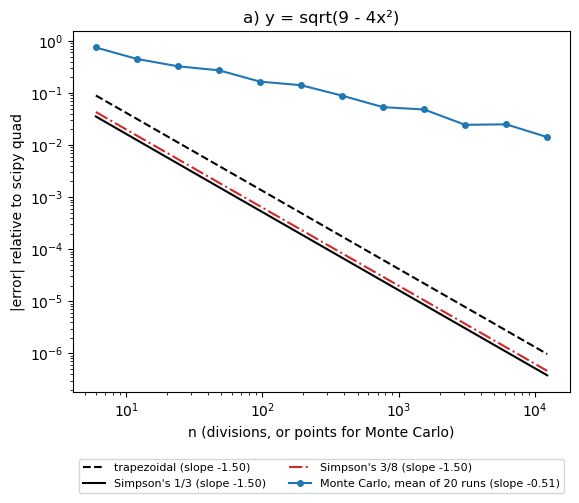

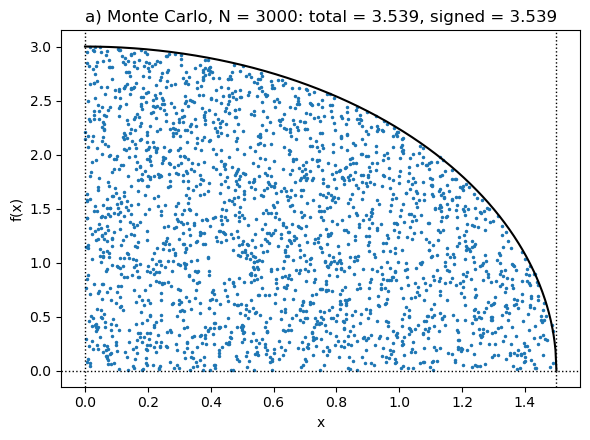

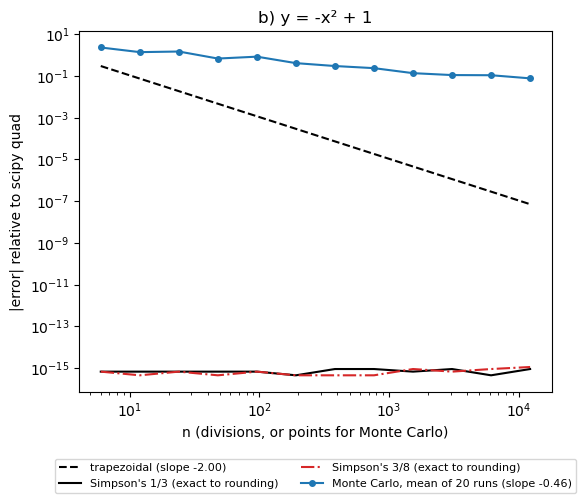

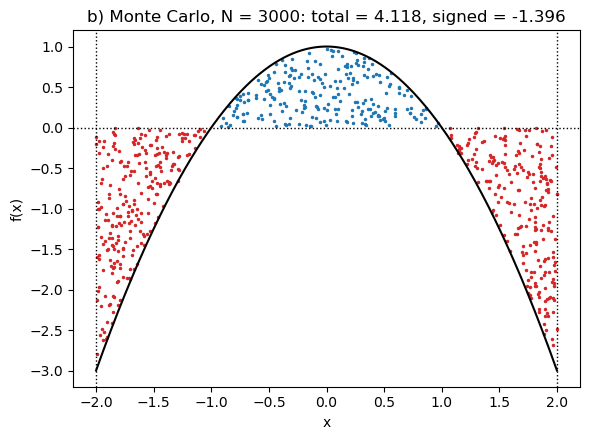

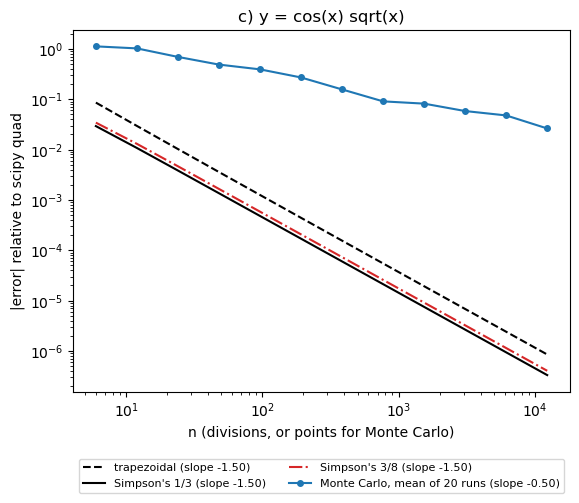

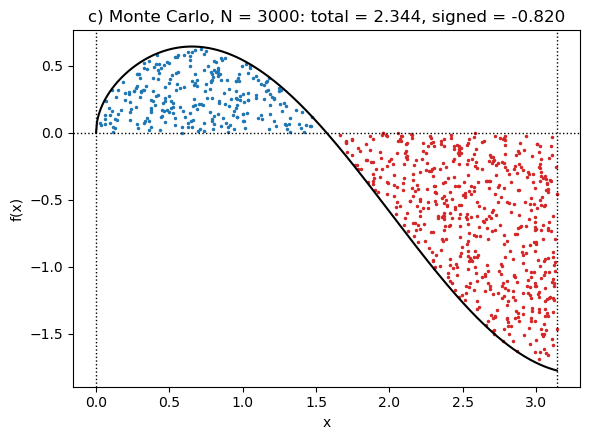

In [5]:
ns = 6*2**np.arange(0, 12)                   # n = 6, 12, ..., 12288: valid for every rule

def error_plot(key):
    f, a, b, label = tests[key]
    exact = reference[key][1]                  # integral from scipy.integrate.quad
    fig, ax = plt.subplots(figsize=(6, 5.2))
    for rule, style, name in ((trapezoidal, 'k--', 'trapezoidal'), (simpson, 'k-', "Simpson's 1/3"),
                              (simpson38, 'C3-.', "Simpson's 3/8")):
        err = np.array([abs(rule(f, a, b, n)[1] - exact) for n in ns])
        err = np.maximum(err, 1e-16)            # an exact result (error 0) is drawn at the rounding floor
        if err.max() < 1e-12:                   # no trend to fit when the rule is exact
            tag = 'exact to rounding'
        else:                                   # order of convergence from a fit over n >= 192
            tag = f'slope {np.polyfit(np.log(ns[5:]), np.log(err[5:]), 1)[0]:.2f}'
        ax.loglog(ns, err, style, label=f'{name} ({tag})')
    # Monte Carlo is random, so its |error| is averaged over 20 runs for each number of points
    err_mc = np.array([np.mean([abs(monte_carlo(f, a, b, n, seed=s)[1] - exact) for s in range(20)]) for n in ns])
    slope_mc = np.polyfit(np.log(ns), np.log(err_mc), 1)[0]
    ax.loglog(ns, err_mc, 'o-', color='C0', ms=4, label=f'Monte Carlo, mean of 20 runs (slope {slope_mc:.2f})')
    ax.set(xlabel='n (divisions, or points for Monte Carlo)', ylabel='|error| relative to scipy quad', title=f'{key}) {label}')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8)   # below the axes, clear of the data
    fig.tight_layout()
    fig.savefig(f'int_{key}_error.png', dpi=120)
    plt.show()


def mc_plot(key, n_points=3000):
    f, a, b, label = tests[key]
    total, signed, (x, y, above, below) = monte_carlo(f, a, b, n_points, seed=1, return_points=True)
    xs = np.linspace(a, b, 500)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot(x[above], y[above], '.', color='C0', ms=3)
    ax.plot(x[below], y[below], '.', color='C3', ms=3)
    ax.plot(xs, evaluate(f, xs), 'k')
    ax.axhline(0, color='k', ls=':', lw=1)
    for xb in (a, b):
        ax.axvline(xb, color='k', ls=':', lw=1)
    ax.set(xlabel='x', ylabel='f(x)',
           title=f'{key}) Monte Carlo, N = {n_points}: total = {total:.3f}, signed = {signed:.3f}')
    fig.tight_layout()
    fig.savefig(f'int_{key}_mc.png', dpi=120)
    plt.show()


for key in tests:
    error_plot(key)
    mc_plot(key)

#### Problem code summary

The code computes the total and signed areas under any function with four methods: the trapezoidal rule, Simpson's 1/3 and 3/8 rules and hit-or-miss Monte Carlo. The three grid rules share one weighted-sum function because they differ only in their weights, and applying that sum to |f| gives the total area without having to locate the roots. Every result is checked against scipy, and the error plots compare how fast each method converges, which depends on the smoothness of the integrand as well as on the method.